# Geometric Transformations

Geometric transformations move pixels to new positions: resizing, cropping, flipping, rotating, and the more general affine and perspective warps used to straighten documents and align images. This notebook covers each one with the exact function and flags you will actually use.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Resizing and scaling

`cv2.resize` takes the target size as (width, height) - the opposite order of shape. Interpolation matters: `INTER_AREA` is best for shrinking, `INTER_LINEAR` or `INTER_CUBIC` for enlarging. Use `fx`/`fy` scale factors when you only know the ratio.

Original: (300, 400, 3) | Small: (150, 200, 3) | Big: (450, 600, 3)


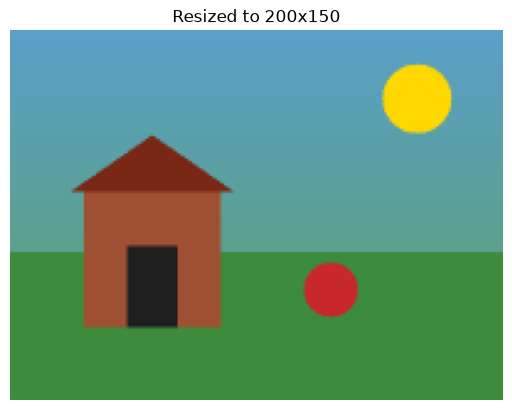

In [2]:
img = cv2.imread("../assets/test_image.png")
small = cv2.resize(img, (200, 150), interpolation=cv2.INTER_AREA)
big = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
print("Original:", img.shape, "| Small:", small.shape, "| Big:", big.shape)
show(small, "Resized to 200x150")

## Cropping and flipping

Cropping is plain NumPy slicing - no function needed. `cv2.flip` mirrors an image: flip code 1 = horizontal, 0 = vertical, -1 = both. Flipping is a very common data-augmentation step.

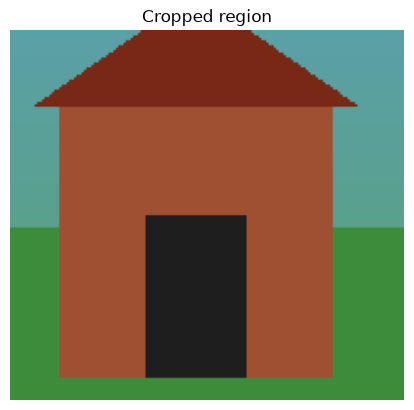

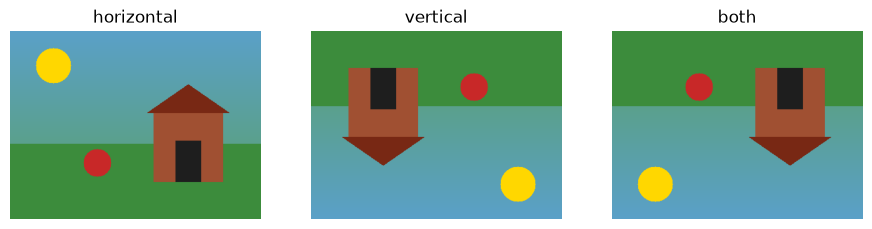

In [3]:
crop = img[100:250, 40:200]
show(crop, "Cropped region")
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, code, name in zip(axes, (1, 0, -1), ("horizontal", "vertical", "both")):
    axes_img = cv2.cvtColor(cv2.flip(img, code), cv2.COLOR_BGR2RGB)
    ax.imshow(axes_img); ax.set_title(name); ax.axis("off")
plt.show()

## Translation and rotation with warpAffine

An affine transform is a 2x3 matrix applied with `cv2.warpAffine`. Translation simply adds an offset. For rotation, `cv2.getRotationMatrix2D(centre, angle, scale)` builds the matrix - positive angles rotate counter-clockwise.

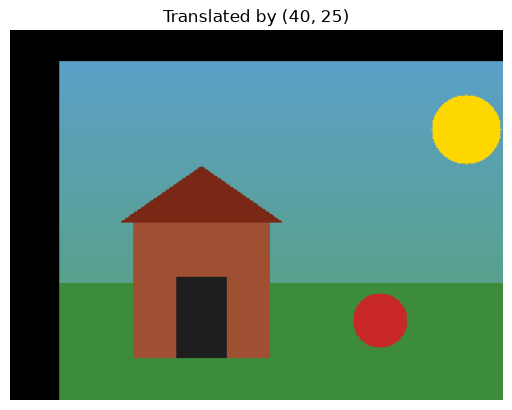

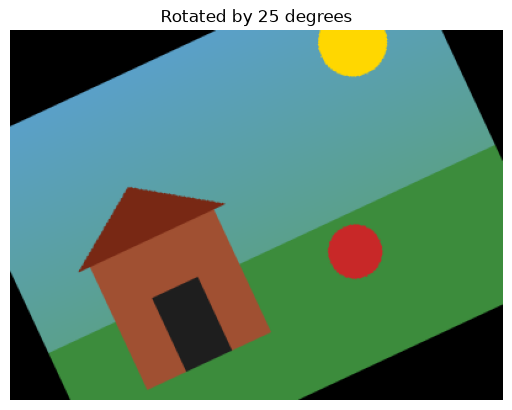

In [4]:
h, w = img.shape[:2]
M_translate = np.float32([[1, 0, 40], [0, 1, 25]])
shifted = cv2.warpAffine(img, M_translate, (w, h))
M_rotate = cv2.getRotationMatrix2D((w // 2, h // 2), 25, 1.0)
rotated = cv2.warpAffine(img, M_rotate, (w, h))
show(shifted, "Translated by (40, 25)")
show(rotated, "Rotated by 25 degrees")

## Perspective transformation

Perspective warping maps four source corners to four destination corners with `cv2.getPerspectiveTransform` + `cv2.warpPerspective`. This is how document scanners flatten a photographed page. The full automatic version is built as a project in notebook 17; here the corners are given.

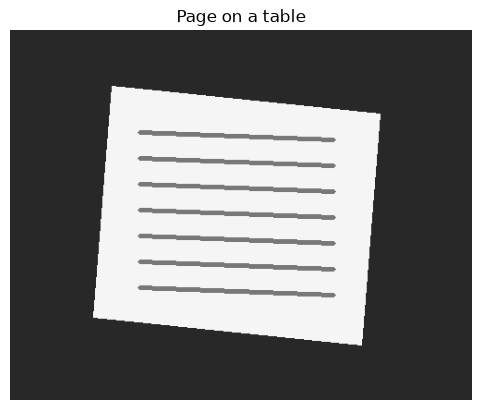

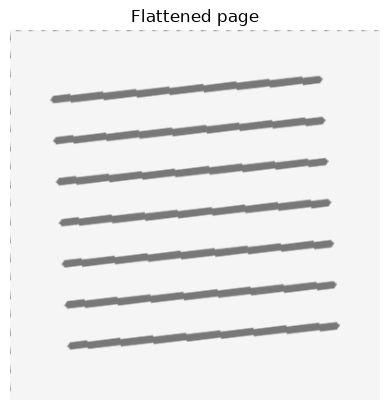

In [5]:
src = np.float32([[110, 60], [400, 90], [380, 340], [90, 310]])
dst = np.float32([[0, 0], [400, 0], [400, 400], [0, 400]])
doc = cv2.imread("../assets/document.png")
M = cv2.getPerspectiveTransform(src, dst)
flat = cv2.warpPerspective(doc, M, (400, 400))
show(doc, "Page on a table")
show(flat, "Flattened page")

## Remapping and image pyramids

`cv2.resize` by exactly half/double repeatedly forms an image pyramid - used by detectors that must find objects at many scales. `cv2.pyrDown` blurs then halves; `cv2.pyrUp` doubles. Information lost in pyrDown cannot be recovered by pyrUp.

Original: (300, 400, 3) | pyrDown x2: (75, 100, 3) | back up: (150, 200, 3)


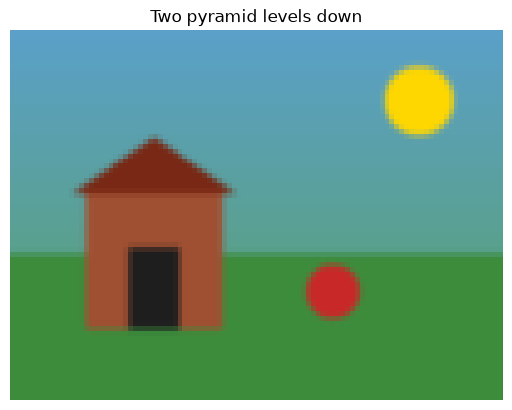

In [6]:
level1 = cv2.pyrDown(img)
level2 = cv2.pyrDown(level1)
back_up = cv2.pyrUp(level2)
print("Original:", img.shape, "| pyrDown x2:", level2.shape, "| back up:", back_up.shape)
show(level2, "Two pyramid levels down")

## Aspect ratio and letterboxing

Resizing to a fixed square distorts objects unless you keep the aspect ratio. The standard fix: scale by the smaller ratio and pad the rest - called letterboxing. Detectors that need fixed input sizes rely on it.

Letterboxed shape: (300, 300, 3)


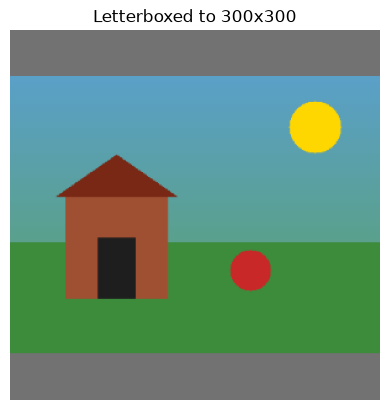

In [7]:
def letterbox(image, size=300):
    h, w = image.shape[:2]
    scale = size / max(h, w)
    resized = cv2.resize(image, (int(w * scale), int(h * scale)))
    canvas = np.full((size, size, 3), 114, np.uint8)
    y, x = (size - resized.shape[0]) // 2, (size - resized.shape[1]) // 2
    canvas[y:y + resized.shape[0], x:x + resized.shape[1]] = resized
    return canvas

boxed = letterbox(img)
print("Letterboxed shape:", boxed.shape)
show(boxed, "Letterboxed to 300x300")

## Key Points

- resize takes (width, height); INTER_AREA for shrinking, INTER_CUBIC/LINEAR for enlarging.
- Cropping is NumPy slicing; flip codes: 1 horizontal, 0 vertical, -1 both.
- Affine transforms (translation, rotation, scaling) use a 2x3 matrix and warpAffine.
- Perspective transforms use 4 point pairs and warpPerspective - the document-scanner core.
- Letterboxing preserves aspect ratio by scaling plus padding.

## Mini Task

1. Rotate `test_image.png` by 45 degrees around its centre and display it.
2. Build a 2-level pyramid and print every shape.
3. Letterbox `shapes.png` to 256x256 and check the output shape is exactly (256, 256, 3).